# Prapemrosesan Data Harian NASA POWER Kota Semarang

Notebook ini berisi tahap prapemrosesan untuk artikel *Klasifikasi Curah Hujan Harian Semarang Menggunakan XGBoost
dengan Penanganan Class Imbalance dan Seleksi Fitur*. Tahapannya:

1. Membaca dan meninjau data
2. Pemeriksaan kualitas data
3. Validasi fisik
4. Statistik deskriptif, *outlier*, dan *skewness*
5. Korelasi antarfitur
6. Pelabelan
7. Pembagian data secara kronologis
8. Menyimpan hasil

Data: NASA POWER harian, koordinat 7,06° LS dan 110,45° BT, periode 1 Januari 2016–31 Desember 2025.

## Import dan Pengaturan

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

In [2]:
FILE_DATA = Path("data") / "DATAFINAL1.csv"
FOLDER_HASIL = Path("hasil")
FOLDER_HASIL.mkdir(exist_ok=True)

NILAI_KOSONG_NASA = -999        # penanda data kosong pada NASA POWER
AMBANG_PELABELAN_MM = 1.0       # hari tanpa hujan < 1 mm (Peraturan BMKG No. 9 Tahun 2019, ETCCDI)
TAHUN_AKHIR_LATIH = 2022        # data latih 2016–2022
TAHUN_AKHIR_VALIDASI = 2024     # data validasi 2023–2024, data uji 2025

## 1. Membaca dan Meninjau Data

Kolom `YEAR` dan `DOY` (hari ke-*n* dalam satu tahun) digabung menjadi kolom tanggal `DATE`.

In [3]:
df = pd.read_csv(FILE_DATA)
tanggal = pd.to_datetime(df["YEAR"].astype(str) + df["DOY"].astype(str).str.zfill(3), format="%Y%j")
df.insert(0, "DATE", tanggal)

print(f"Jumlah baris : {len(df)}")
print(f"Jumlah kolom : {df.shape[1] - 1} (di luar kolom DATE)")
print(f"Periode      : {df['DATE'].min():%d-%m-%Y} s.d. {df['DATE'].max():%d-%m-%Y}")

Jumlah baris : 3653
Jumlah kolom : 22 (di luar kolom DATE)
Periode      : 01-01-2016 s.d. 31-12-2025


In [4]:
df.head()

,DATE,YEAR,DOY,T2M,T2M_MAX,T2M_MIN,QV2M,PS,WS2M,WS2M_MAX,WS2M_MIN,WS10M,WD2M,WD10M,RH2M,T2MDEW,T2MWET,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_LW_DWN,ALLSKY_SFC_UV_INDEX,ALLSKY_SFC_PAR_TOT,T2M_RANGE,PRECTOTCORR
0,2016-01-01,2016,1,28.12,31.63,25.50,18.80,99.62,1.14,2.32,0.34,1.60,-6660.0,-6627.0,79.02,23.96,26.04,17.84,35.86,2.09,8.34,6.13,2.76
1,2016-01-02,2016,2,27.10,29.13,25.45,19.02,99.66,1.22,1.81,0.38,1.68,-5554.0,-5670.0,84.26,24.16,25.63,18.91,35.62,2.12,8.74,3.68,4.81
2,2016-01-03,2016,3,27.40,30.38,25.59,19.05,99.69,1.14,2.00,0.19,1.63,-6335.0,-6304.0,83.21,24.19,25.80,20.56,35.47,2.33,9.55,4.79,30.72
3,2016-01-04,2016,4,27.17,29.14,25.44,19.13,99.69,0.81,1.15,0.16,1.17,-5492.0,-5536.0,84.51,24.26,25.71,17.07,36.04,1.85,7.80,3.70,17.91
4,2016-01-05,2016,5,26.94,29.16,25.35,19.30,99.65,1.24,2.61,0.65,1.73,-8852.0,-8866.0,86.20,24.40,25.67,17.30,35.75,1.80,7.81,3.81,8.16


In [5]:
df.tail()

,DATE,YEAR,DOY,T2M,T2M_MAX,T2M_MIN,QV2M,PS,WS2M,WS2M_MAX,WS2M_MIN,WS10M,WD2M,WD10M,RH2M,T2MDEW,T2MWET,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_LW_DWN,ALLSKY_SFC_UV_INDEX,ALLSKY_SFC_PAR_TOT,T2M_RANGE,PRECTOTCORR
3648,2025-12-27,2025,361,26.94,28.98,25.47,19.38,99.29,1.89,3.99,0.30,2.61,-6251.0,-6251.0,86.19,24.40,25.67,15.08,36.05,2.01,7.10,3.51,8.30
3649,2025-12-28,2025,362,27.00,29.35,24.97,19.07,99.33,1.20,1.94,0.49,1.69,-5899.0,-5923.0,84.66,24.15,25.57,21.16,35.79,2.73,9.92,4.38,1.52
3650,2025-12-29,2025,363,26.77,29.13,25.30,18.89,99.28,1.07,1.85,0.29,1.54,-6373.0,-6400.0,84.93,23.98,25.38,20.45,35.95,2.67,9.57,3.83,1.85
3651,2025-12-30,2025,364,26.29,28.79,24.66,18.42,99.24,1.47,2.76,0.89,2.07,-5924.0,-5950.0,85.29,23.57,24.93,18.30,35.81,2.41,8.56,4.13,0.96
3652,2025-12-31,2025,365,25.59,27.43,24.37,18.72,99.23,2.63,4.57,0.33,3.58,-5827.0,-5829.0,89.98,23.82,24.70,10.74,35.76,1.53,5.23,3.06,27.84


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3653 entries, 0 to 3652
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   DATE                 3653 non-null   datetime64[us]
 1   YEAR                 3653 non-null   int64         
 2   DOY                  3653 non-null   int64         
 3   T2M                  3653 non-null   float64       
 4   T2M_MAX              3653 non-null   float64       
 5   T2M_MIN              3653 non-null   float64       
 6   QV2M                 3653 non-null   float64       
 7   PS                   3653 non-null   float64       
 8   WS2M                 3653 non-null   float64       
 9   WS2M_MAX             3653 non-null   float64       
 10  WS2M_MIN             3653 non-null   float64       
 11  WS10M                3653 non-null   float64       
 12  WD2M                 3653 non-null   float64       
 13  WD10M                3653 non-null   float64

## 2. Pemeriksaan Kualitas Data

### 2.1 Nilai kosong dan nilai -999

In [7]:
kolom_angka = df.select_dtypes("number").columns

kualitas = pd.DataFrame({
    "Nilai kosong": df[kolom_angka].isna().sum(),
    f"Nilai {NILAI_KOSONG_NASA}": (df[kolom_angka] == NILAI_KOSONG_NASA).sum(),
})
kualitas

,Nilai kosong,Nilai -999
YEAR,0,0
DOY,0,0
T2M,0,0
T2M_MAX,0,0
T2M_MIN,0,0
QV2M,0,0
PS,0,0
WS2M,0,0
WS2M_MAX,0,0
WS2M_MIN,0,0


In [8]:
print("Total nilai kosong :", int(kualitas["Nilai kosong"].sum()))
print(f"Total nilai {NILAI_KOSONG_NASA}  :", int(kualitas[f"Nilai {NILAI_KOSONG_NASA}"].sum()))

Total nilai kosong : 0
Total nilai -999  : 0


### 2.2 Duplikasi dan kelengkapan kalender

In [9]:
kalender_lengkap = pd.date_range(df["DATE"].min(), df["DATE"].max(), freq="D")
tanggal_hilang = kalender_lengkap.difference(df["DATE"])

print("Baris duplikat   :", df.duplicated().sum())
print("Tanggal duplikat :", df["DATE"].duplicated().sum())
print("Tanggal hilang   :", len(tanggal_hilang))
print("Hari seharusnya  :", len(kalender_lengkap), "| hari tersedia:", len(df))

Baris duplikat   : 0
Tanggal duplikat : 0
Tanggal hilang   : 0
Hari seharusnya  : 3653 | hari tersedia: 3653


## 3. Validasi Fisik

Setiap parameter diperiksa terhadap rentang yang masuk akal secara fisik. Parameter yang gagal validasi
tidak dipakai sebagai fitur.

In [10]:
RENTANG_FISIK = {
    "RH2M": (0, 100),
    "WD2M": (0, 360),
    "WD10M": (0, 360),
    "WS2M": (0, None),
    "WS2M_MAX": (0, None),
    "WS2M_MIN": (0, None),
    "WS10M": (0, None),
    "QV2M": (0, None),
    "PS": (0, None),
    "ALLSKY_SFC_SW_DWN": (0, None),
    "ALLSKY_SFC_LW_DWN": (0, None),
    "ALLSKY_SFC_PAR_TOT": (0, None),
    "ALLSKY_SFC_UV_INDEX": (0, None),
    "T2M_RANGE": (0, None),
    "PRECTOTCORR": (0, None),
}


def hitung_pelanggaran_rentang(data, rentang):
    hasil = []
    for kolom, (batas_bawah, batas_atas) in rentang.items():
        pelanggaran = data[kolom] < batas_bawah
        if batas_atas is not None:
            pelanggaran |= data[kolom] > batas_atas
        hasil.append({
            "Parameter": kolom,
            "Rentang": f"{batas_bawah}–{batas_atas if batas_atas is not None else '∞'}",
            "Min": data[kolom].min(),
            "Maks": data[kolom].max(),
            "Pelanggaran": int(pelanggaran.sum()),
        })
    return pd.DataFrame(hasil)


validasi_rentang = hitung_pelanggaran_rentang(df, RENTANG_FISIK)
validasi_rentang

,Parameter,Rentang,Min,Maks,Pelanggaran
0,RH2M,0–100,48.81,93.64,0
1,WD2M,0–360,-8998.00,-5404.00,3653
2,WD10M,0–360,-8999.00,-5400.00,3653
3,WS2M,0–∞,0.47,4.88,0
4,WS2M_MAX,0–∞,0.77,7.13,0
5,WS2M_MIN,0–∞,0.02,3.38,0
6,WS10M,0–∞,0.64,6.68,0
7,QV2M,0–∞,10.72,20.73,0
8,PS,0–∞,98.93,99.84,0
9,ALLSKY_SFC_SW_DWN,0–∞,5.71,27.87,0


In [11]:
validasi_konsistensi = pd.Series({
    "T2M_MIN > T2M": (df["T2M_MIN"] > df["T2M"]).sum(),
    "T2M > T2M_MAX": (df["T2M"] > df["T2M_MAX"]).sum(),
    "T2MDEW > T2M": (df["T2MDEW"] > df["T2M"]).sum(),
    "WS2M_MIN > WS2M": (df["WS2M_MIN"] > df["WS2M"]).sum(),
    "WS2M > WS2M_MAX": (df["WS2M"] > df["WS2M_MAX"]).sum(),
    "T2M_RANGE ≠ T2M_MAX − T2M_MIN": (
        (df["T2M_MAX"] - df["T2M_MIN"] - df["T2M_RANGE"]).abs() > 0.01
    ).sum(),
}, name="Pelanggaran")
validasi_konsistensi.to_frame()

,Pelanggaran
T2M_MIN > T2M,0
T2M > T2M_MAX,0
T2MDEW > T2M,0
WS2M_MIN > WS2M,0
WS2M > WS2M_MAX,0
T2M_RANGE ≠ T2M_MAX − T2M_MIN,0


In [12]:
PARAMETER_GAGAL = validasi_rentang.loc[validasi_rentang["Pelanggaran"] > 0, "Parameter"].tolist()
KOLOM_LABEL_SUMBER = "PRECTOTCORR"
KOLOM_NON_FITUR = ["DATE", "YEAR", "DOY", KOLOM_LABEL_SUMBER]

FITUR = [kolom for kolom in df.columns if kolom not in KOLOM_NON_FITUR + PARAMETER_GAGAL]

print("Parameter gagal validasi :", PARAMETER_GAGAL)
for kolom in PARAMETER_GAGAL:
    jumlah_negatif = (df[kolom] < 0).sum()
    print(f"  {kolom}: {jumlah_negatif} dari {len(df)} nilai negatif, "
          f"rentang {df[kolom].min():.0f} sampai {df[kolom].max():.0f}")
print(f"\nJumlah fitur yang dipakai: {len(FITUR)}")
print(FITUR)

Parameter gagal validasi : ['WD2M', 'WD10M']
  WD2M: 3653 dari 3653 nilai negatif, rentang -8998 sampai -5404
  WD10M: 3653 dari 3653 nilai negatif, rentang -8999 sampai -5400

Jumlah fitur yang dipakai: 17
['T2M', 'T2M_MAX', 'T2M_MIN', 'QV2M', 'PS', 'WS2M', 'WS2M_MAX', 'WS2M_MIN', 'WS10M', 'RH2M', 'T2MDEW', 'T2MWET', 'ALLSKY_SFC_SW_DWN', 'ALLSKY_SFC_LW_DWN', 'ALLSKY_SFC_UV_INDEX', 'ALLSKY_SFC_PAR_TOT', 'T2M_RANGE']


## 4. Statistik Deskriptif, *Outlier*, dan *Skewness*

In [13]:
def hitung_outlier_iqr(kolom):
    q1, q3 = kolom.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((kolom < q1 - 1.5 * iqr) | (kolom > q3 + 1.5 * iqr)).sum())


kolom_statistik = FITUR + [KOLOM_LABEL_SUMBER]
statistik = df[kolom_statistik].describe().T
statistik["skewness"] = df[kolom_statistik].skew()
statistik["outlier_IQR"] = [hitung_outlier_iqr(df[kolom]) for kolom in kolom_statistik]
statistik.round(3)

,count,mean,std,min,25%,50%,75%,max,skewness,outlier_IQR
T2M,3653.0,26.963,1.115,24.04,26.23,26.77,27.41,31.80,1.239,189
T2M_MAX,3653.0,30.607,2.382,25.78,28.99,30.10,31.47,38.91,1.130,252
T2M_MIN,3653.0,24.062,1.115,19.31,23.49,24.27,24.82,27.27,-0.811,113
QV2M,3653.0,17.726,1.707,10.72,17.12,18.22,18.86,20.73,-1.292,270
PS,3653.0,99.402,0.132,98.93,99.31,99.41,99.50,99.84,-0.239,10
WS2M,3653.0,1.867,0.635,0.47,1.37,1.84,2.26,4.88,0.564,41
WS2M_MAX,3653.0,2.981,0.889,0.77,2.32,2.96,3.56,7.13,0.439,38
WS2M_MIN,3653.0,0.842,0.513,0.02,0.43,0.81,1.15,3.38,0.834,56
WS10M,3653.0,2.559,0.856,0.64,1.91,2.53,3.10,6.68,0.576,43
RH2M,3653.0,79.986,9.076,48.81,77.36,82.57,85.89,93.64,-1.471,319


In [14]:
curah_hujan = df[KOLOM_LABEL_SUMBER]

print(f"Rata-rata : {curah_hujan.mean():.2f} mm/hari")
print(f"Median    : {curah_hujan.median():.2f} mm/hari")
print(f"Maksimum  : {curah_hujan.max():.2f} mm/hari")
print(f"Skewness  : {curah_hujan.skew():.3f}")
print(f"Outlier (metode IQR): {hitung_outlier_iqr(curah_hujan)} hari")

Rata-rata : 6.36 mm/hari
Median    : 2.35 mm/hari
Maksimum  : 117.11 mm/hari
Skewness  : 3.726
Outlier (metode IQR): 347 hari


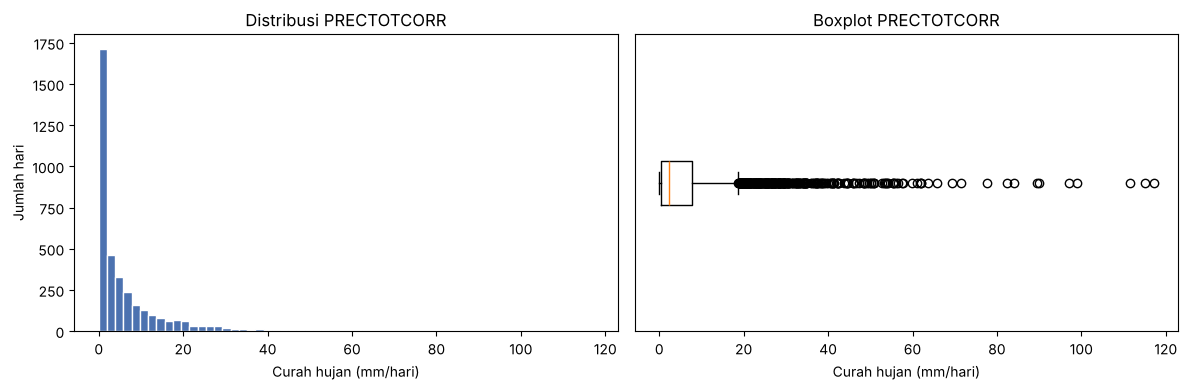

In [15]:
fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(12, 4))

ax_hist.hist(curah_hujan, bins=60, color="#4C72B0", edgecolor="white")
ax_hist.set(title="Distribusi PRECTOTCORR", xlabel="Curah hujan (mm/hari)", ylabel="Jumlah hari")

ax_box.boxplot(curah_hujan, orientation="horizontal")
ax_box.set(title="Boxplot PRECTOTCORR", xlabel="Curah hujan (mm/hari)", yticks=[])

plt.tight_layout()
plt.savefig(FOLDER_HASIL / "distribusi_prectotcorr.png", dpi=200)
plt.show()

Distribusi curah hujan sangat menceng ke kanan. Nilai ekstrem tidak dihapus karena curah hujan harian
di atas 100 mm masih wajar terjadi pada musim hujan, dan menghapusnya akan menghilangkan kejadian hujan lebat
yang sebenarnya. Nilai ekstrem pada fitur lain juga dipertahankan dengan alasan yang sama.

## 5. Korelasi Antarfitur

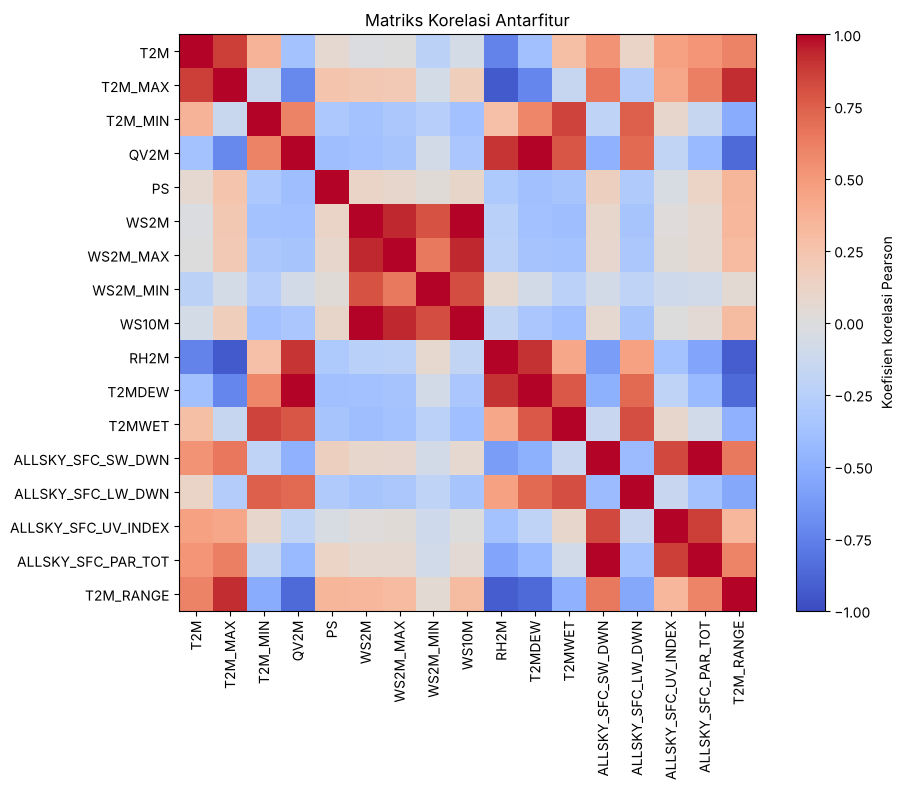

In [16]:
korelasi = df[FITUR].corr()

fig, ax = plt.subplots(figsize=(10, 8))
gambar = ax.imshow(korelasi, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(FITUR)), FITUR, rotation=90)
ax.set_yticks(range(len(FITUR)), FITUR)
fig.colorbar(gambar, label="Koefisien korelasi Pearson")
ax.set_title("Matriks Korelasi Antarfitur")
plt.tight_layout()
plt.savefig(FOLDER_HASIL / "matriks_korelasi.png", dpi=200)
plt.show()

In [17]:
segitiga_atas = korelasi.where(np.triu(np.ones(korelasi.shape, dtype=bool), k=1))
pasangan_kuat = (
    segitiga_atas.stack()
    .rename("Korelasi")
    .reset_index()
    .rename(columns={"level_0": "Fitur 1", "level_1": "Fitur 2"})
)
pasangan_kuat = pasangan_kuat[pasangan_kuat["Korelasi"].abs() >= 0.8]
pasangan_kuat.sort_values("Korelasi", key=abs, ascending=False).round(3).reset_index(drop=True)

,Fitur 1,Fitur 2,Korelasi
0,QV2M,T2MDEW,0.998
1,WS2M,WS10M,0.998
2,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_PAR_TOT,0.996
3,WS2M,WS2M_MAX,0.936
4,T2M_MAX,RH2M,-0.933
5,WS2M_MAX,WS10M,0.932
6,T2M_MAX,T2M_RANGE,0.917
7,RH2M,T2M_RANGE,-0.915
8,RH2M,T2MDEW,0.899
9,QV2M,RH2M,0.893


Pasangan dengan korelasi mendekati 1 bersifat redundan. Pasangan ini tidak dibuang pada tahap prapemrosesan,
tetapi diperiksa saat seleksi fitur.

## 6. Pelabelan

Hari berlabel **Hujan (1)** jika PRECTOTCORR ≥ 1 mm dan **Tidak Hujan (0)** jika PRECTOTCORR < 1 mm.

In [18]:
NAMA_KELAS = {0: "Tidak Hujan", 1: "Hujan"}

df["Label"] = (df[KOLOM_LABEL_SUMBER] >= AMBANG_PELABELAN_MM).astype(int)

distribusi_label = df["Label"].value_counts().sort_index().rename(index=NAMA_KELAS).to_frame("Jumlah hari")
distribusi_label["Persentase (%)"] = (distribusi_label["Jumlah hari"] / len(df) * 100).round(2)
distribusi_label

,Jumlah hari,Persentase (%)
Label,,
Tidak Hujan,1293,35.4
Hujan,2360,64.6


In [19]:
kolom_contoh = ["DATE", "T2M", "T2M_MAX", "T2M_MIN", "ALLSKY_SFC_PAR_TOT", "T2M_RANGE", KOLOM_LABEL_SUMBER, "Label"]
pd.concat([df[kolom_contoh].head(), df[kolom_contoh].tail()])

,DATE,T2M,T2M_MAX,T2M_MIN,ALLSKY_SFC_PAR_TOT,T2M_RANGE,PRECTOTCORR,Label
0,2016-01-01,28.12,31.63,25.50,8.34,6.13,2.76,1
1,2016-01-02,27.10,29.13,25.45,8.74,3.68,4.81,1
2,2016-01-03,27.40,30.38,25.59,9.55,4.79,30.72,1
3,2016-01-04,27.17,29.14,25.44,7.80,3.70,17.91,1
4,2016-01-05,26.94,29.16,25.35,7.81,3.81,8.16,1
3648,2025-12-27,26.94,28.98,25.47,7.10,3.51,8.30,1
3649,2025-12-28,27.00,29.35,24.97,9.92,4.38,1.52,1
3650,2025-12-29,26.77,29.13,25.30,9.57,3.83,1.85,1
3651,2025-12-30,26.29,28.79,24.66,8.56,4.13,0.96,0
3652,2025-12-31,25.59,27.43,24.37,5.23,3.06,27.84,1


In [20]:
persentase_hujan_per_tahun = df.groupby("YEAR")["Label"].agg(
    hari_hujan="sum",
    persentase_hujan=lambda label: round(label.mean() * 100, 2),
)
persentase_hujan_per_tahun["hari_tidak_hujan"] = df.groupby("YEAR").size() - persentase_hujan_per_tahun["hari_hujan"]
persentase_hujan_per_tahun

,hari_hujan,persentase_hujan,hari_tidak_hujan
YEAR,,,
2016,303,82.79,63
2017,226,61.92,139
2018,187,51.23,178
2019,170,46.58,195
2020,256,69.95,110
2021,250,68.49,115
2022,276,75.62,89
2023,184,50.41,181
2024,239,65.30,127


Sebagai pembanding, distribusi kelas juga dihitung pada beberapa ambang pelabelan lain.

In [21]:
DAFTAR_AMBANG_PEMBANDING = {"> 0 mm": 0.0, "≥ 0,1 mm": 0.1, "≥ 0,5 mm": 0.5, "≥ 1 mm": 1.0}

baris = []
for nama, ambang in DAFTAR_AMBANG_PEMBANDING.items():
    hujan = df[KOLOM_LABEL_SUMBER] > 0 if ambang == 0 else df[KOLOM_LABEL_SUMBER] >= ambang
    baris.append({
        "Ambang pelabelan": nama,
        "Hari Tidak Hujan": int((~hujan).sum()),
        "Hari Hujan": int(hujan.sum()),
        "Rasio H:TH": round(hujan.sum() / (~hujan).sum(), 2),
    })
pd.DataFrame(baris)

,Ambang pelabelan,Hari Tidak Hujan,Hari Hujan,Rasio H:TH
0,> 0 mm,314,3339,10.63
1,"≥ 0,1 mm",632,3021,4.78
2,"≥ 0,5 mm",1002,2651,2.65
3,≥ 1 mm,1293,2360,1.83


## 7. Pembagian Data Secara Kronologis

Data dibagi menurut tahun agar model tidak dilatih dengan data yang waktunya lebih baru daripada data uji.

| Subset | Periode |
|---|---|
| Latih | 2016–2022 |
| Validasi | 2023–2024 |
| Uji | 2025 |

In [22]:
df["Subset"] = np.select(
    [df["YEAR"] <= TAHUN_AKHIR_LATIH, df["YEAR"] <= TAHUN_AKHIR_VALIDASI],
    ["latih", "validasi"],
    default="uji",
)

rentang_subset = df.groupby("Subset", sort=False)["DATE"].agg(["min", "max", "count"])
rentang_subset

,min,max,count
Subset,,,
latih,2016-01-01,2022-12-31,2557
validasi,2023-01-01,2024-12-31,731
uji,2025-01-01,2025-12-31,365


In [23]:
akhir_latih = df.loc[df["Subset"] == "latih", "DATE"].max()
awal_validasi = df.loc[df["Subset"] == "validasi", "DATE"].min()
akhir_validasi = df.loc[df["Subset"] == "validasi", "DATE"].max()
awal_uji = df.loc[df["Subset"] == "uji", "DATE"].min()

assert akhir_latih < awal_validasi and akhir_validasi < awal_uji, "Urutan waktu antarsubset tidak benar"
assert df["Subset"].value_counts().sum() == len(df), "Ada baris yang tidak masuk subset mana pun"
print("Pembagian kronologis valid: tidak ada tanggal yang tumpang tindih antarsubset.")

Pembagian kronologis valid: tidak ada tanggal yang tumpang tindih antarsubset.


In [24]:
def ringkas_distribusi(data):
    jumlah_hari = len(data)
    tidak_hujan = int((data["Label"] == 0).sum())
    hujan = int((data["Label"] == 1).sum())
    tahun_awal, tahun_akhir = data["YEAR"].min(), data["YEAR"].max()
    periode = str(tahun_awal) if tahun_awal == tahun_akhir else f"{tahun_awal}–{tahun_akhir}"
    return pd.Series({
        "Periode": periode,
        "Hari": jumlah_hari,
        "Tidak Hujan": f"{tidak_hujan} ({tidak_hujan / jumlah_hari:.2%})",
        "Hujan": f"{hujan} ({hujan / jumlah_hari:.2%})",
        "Rasio H:TH": f"{hujan / tidak_hujan:.2f}:1",
    })


distribusi_subset = df.groupby("Subset", sort=False).apply(ringkas_distribusi, include_groups=False)
distribusi_subset.loc["total"] = ringkas_distribusi(df)
distribusi_subset

,Periode,Hari,Tidak Hujan,Hujan,Rasio H:TH
Subset,,,,,
latih,2016–2022,2557,889 (34.77%),1668 (65.23%),1.88:1
validasi,2023–2024,731,308 (42.13%),423 (57.87%),1.37:1
uji,2025,365,96 (26.30%),269 (73.70%),2.80:1
total,2016–2025,3653,1293 (35.40%),2360 (64.60%),1.83:1


## 8. Menyimpan Hasil

In [25]:
data_prapemrosesan = df[["DATE"] + FITUR + [KOLOM_LABEL_SUMBER, "Label", "Subset"]]
data_prapemrosesan.to_csv(FOLDER_HASIL / "data_prapemrosesan_1mm.csv", index=False, date_format="%Y-%m-%d")

indeks_pembagian = df[["DATE", "YEAR", "DOY", "Subset"]]
indeks_pembagian.to_csv(FOLDER_HASIL / "indeks_pembagian_data.csv", index=False, date_format="%Y-%m-%d")

print("File tersimpan di folder", FOLDER_HASIL.resolve())
for file in sorted(FOLDER_HASIL.iterdir()):
    print(" -", file.name)

File tersimpan di folder /home/user/github_prapemrosesan/hasil
 - data_prapemrosesan_1mm.csv
 - distribusi_prectotcorr.png
 - indeks_pembagian_data.csv
 - matriks_korelasi.png
